In [14]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/simuteh-2330511058/notebook

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/simuteh-2330511058/notebook


In [23]:
import os
import cv2, numpy as np, skimage, matplotlib.pyplot as plt
from utils_cv import baca, tampil
print(os.getcwd())
print(os.listdir("../src"))
print(len(os.listdir("../data/sintetis/citra")))

/content/drive/MyDrive/simuteh-2330511058/notebook
['buat_dataset_sintetis.py', 'utils_cv.py', '__pycache__', 'praproses.py']
60


In [16]:
import os
import sys

# Pastikan posisi berada di folder notebook
%cd /content/drive/MyDrive/simuteh-2330511058/notebook

# Masukkan folder src ke jalur pencarian Python
sys.path.insert(0, os.path.abspath("../src"))

# Cek apakah file utils_cv.py ditemukan
print(os.listdir("../src"))

from utils_cv import statistik, baca

/content/drive/MyDrive/simuteh-2330511058/notebook
['buat_dataset_sintetis.py', 'utils_cv.py', '__pycache__', 'praproses.py']


**3.1 Statistik dan histogram untuk diagnosis**

teh_041.png {'rerata': 179.0, 'simpangan_baku': 38.5, 'min': 61, 'maks': 237, 'persen_gelap': 0.0, 'persen_terang': 16.6}
teh_042.png {'rerata': 123.9, 'simpangan_baku': 45.7, 'min': 9, 'maks': 189, 'persen_gelap': 16.8, 'persen_terang': 0.0}
teh_043.png {'rerata': 209.3, 'simpangan_baku': 23.8, 'min': 130, 'maks': 252, 'persen_gelap': 0.0, 'persen_terang': 76.3}
teh_044.png {'rerata': 156.8, 'simpangan_baku': 16.0, 'min': 101, 'maks': 196, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 120.0, 'simpangan_baku': 51.3, 'min': 22, 'maks': 245, 'persen_gelap': 1.8, 'persen_terang': 6.4}


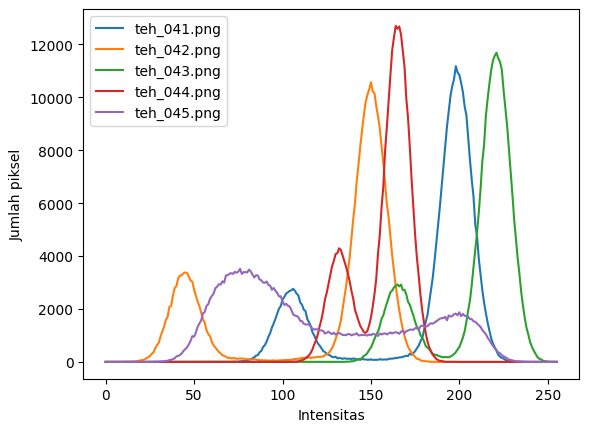

In [25]:
from utils_cv import statistik

for nama in ["teh_041.png", "teh_042.png", "teh_043.png",
             "teh_044.png", "teh_045.png"]:
    gray = cv2.cvtColor(baca(f"../data/sintetis/citra/{nama}"),
                        cv2.COLOR_BGR2GRAY)

    print(nama, statistik(gray))

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.legend()
plt.savefig("../hasil/b3_histogram_5kondisi.png")

teh_021.png {'rerata': 169.9, 'simpangan_baku': 37.7, 'min': 61, 'maks': 231, 'persen_gelap': 0.0, 'persen_terang': 3.1}
teh_022.png {'rerata': 132.4, 'simpangan_baku': 40.3, 'min': 11, 'maks': 195, 'persen_gelap': 7.0, 'persen_terang': 0.0}
teh_023.png {'rerata': 209.3, 'simpangan_baku': 24.0, 'min': 139, 'maks': 245, 'persen_gelap': 0.0, 'persen_terang': 75.2}
teh_024.png {'rerata': 154.3, 'simpangan_baku': 13.9, 'min': 106, 'maks': 186, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_025.png {'rerata': 128.5, 'simpangan_baku': 56.0, 'min': 36, 'maks': 249, 'persen_gelap': 0.2, 'persen_terang': 15.6}


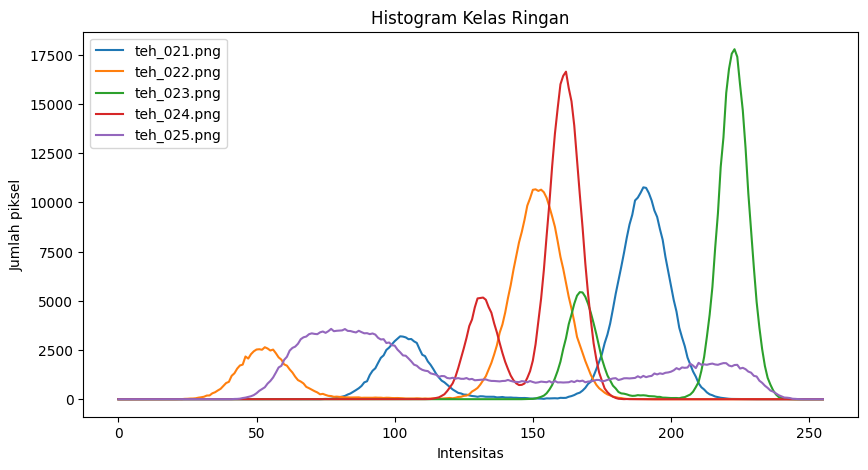

In [26]:
plt.figure(figsize=(10, 5))

for nama in ["teh_021.png", "teh_022.png", "teh_023.png",
             "teh_024.png", "teh_025.png"]:
    gray = cv2.cvtColor(
        baca(f"../data/sintetis/citra/{nama}"),
        cv2.COLOR_BGR2GRAY
    )

    print(nama, statistik(gray))

    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.legend()
plt.title("Histogram Kelas Ringan")
plt.savefig("../hasil/b3_histogram_5kondisi_ringan.png")
plt.show()

##**Kode 3.2 Operasi titik, peregangan, gamma, ekualisasi, dan CLAHE**

In [27]:
nama = "teh_045.png"  # kondisi bayangan
img = baca(f"../data/sintetis/citra/{nama}")

md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)


def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)


rmin, rmax = np.percentile(gray, (2, 98))  # abaikan 2% piksel ekstrem

hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip(
        (gray - rmin) / (rmax - rmin) * 255,
        0, 255
    ).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    ).apply(gray),
}

for nm, c in hasil.items():
    print(
        f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} "
        f"sigma={c.std():.1f}"
    )

asli       KB=1.50 sigma=51.3
negatif    KB=1.50 sigma=51.3
cerah+50   KB=1.50 sigma=50.4
kontras    KB=1.50 sigma=73.7
regang     KB=1.53 sigma=78.8
gamma0.5   KB=1.33 sigma=37.1
gamma1.8   KB=1.79 sigma=54.6
ekualisasi KB=1.15 sigma=73.4
CLAHE      KB=2.09 sigma=44.6


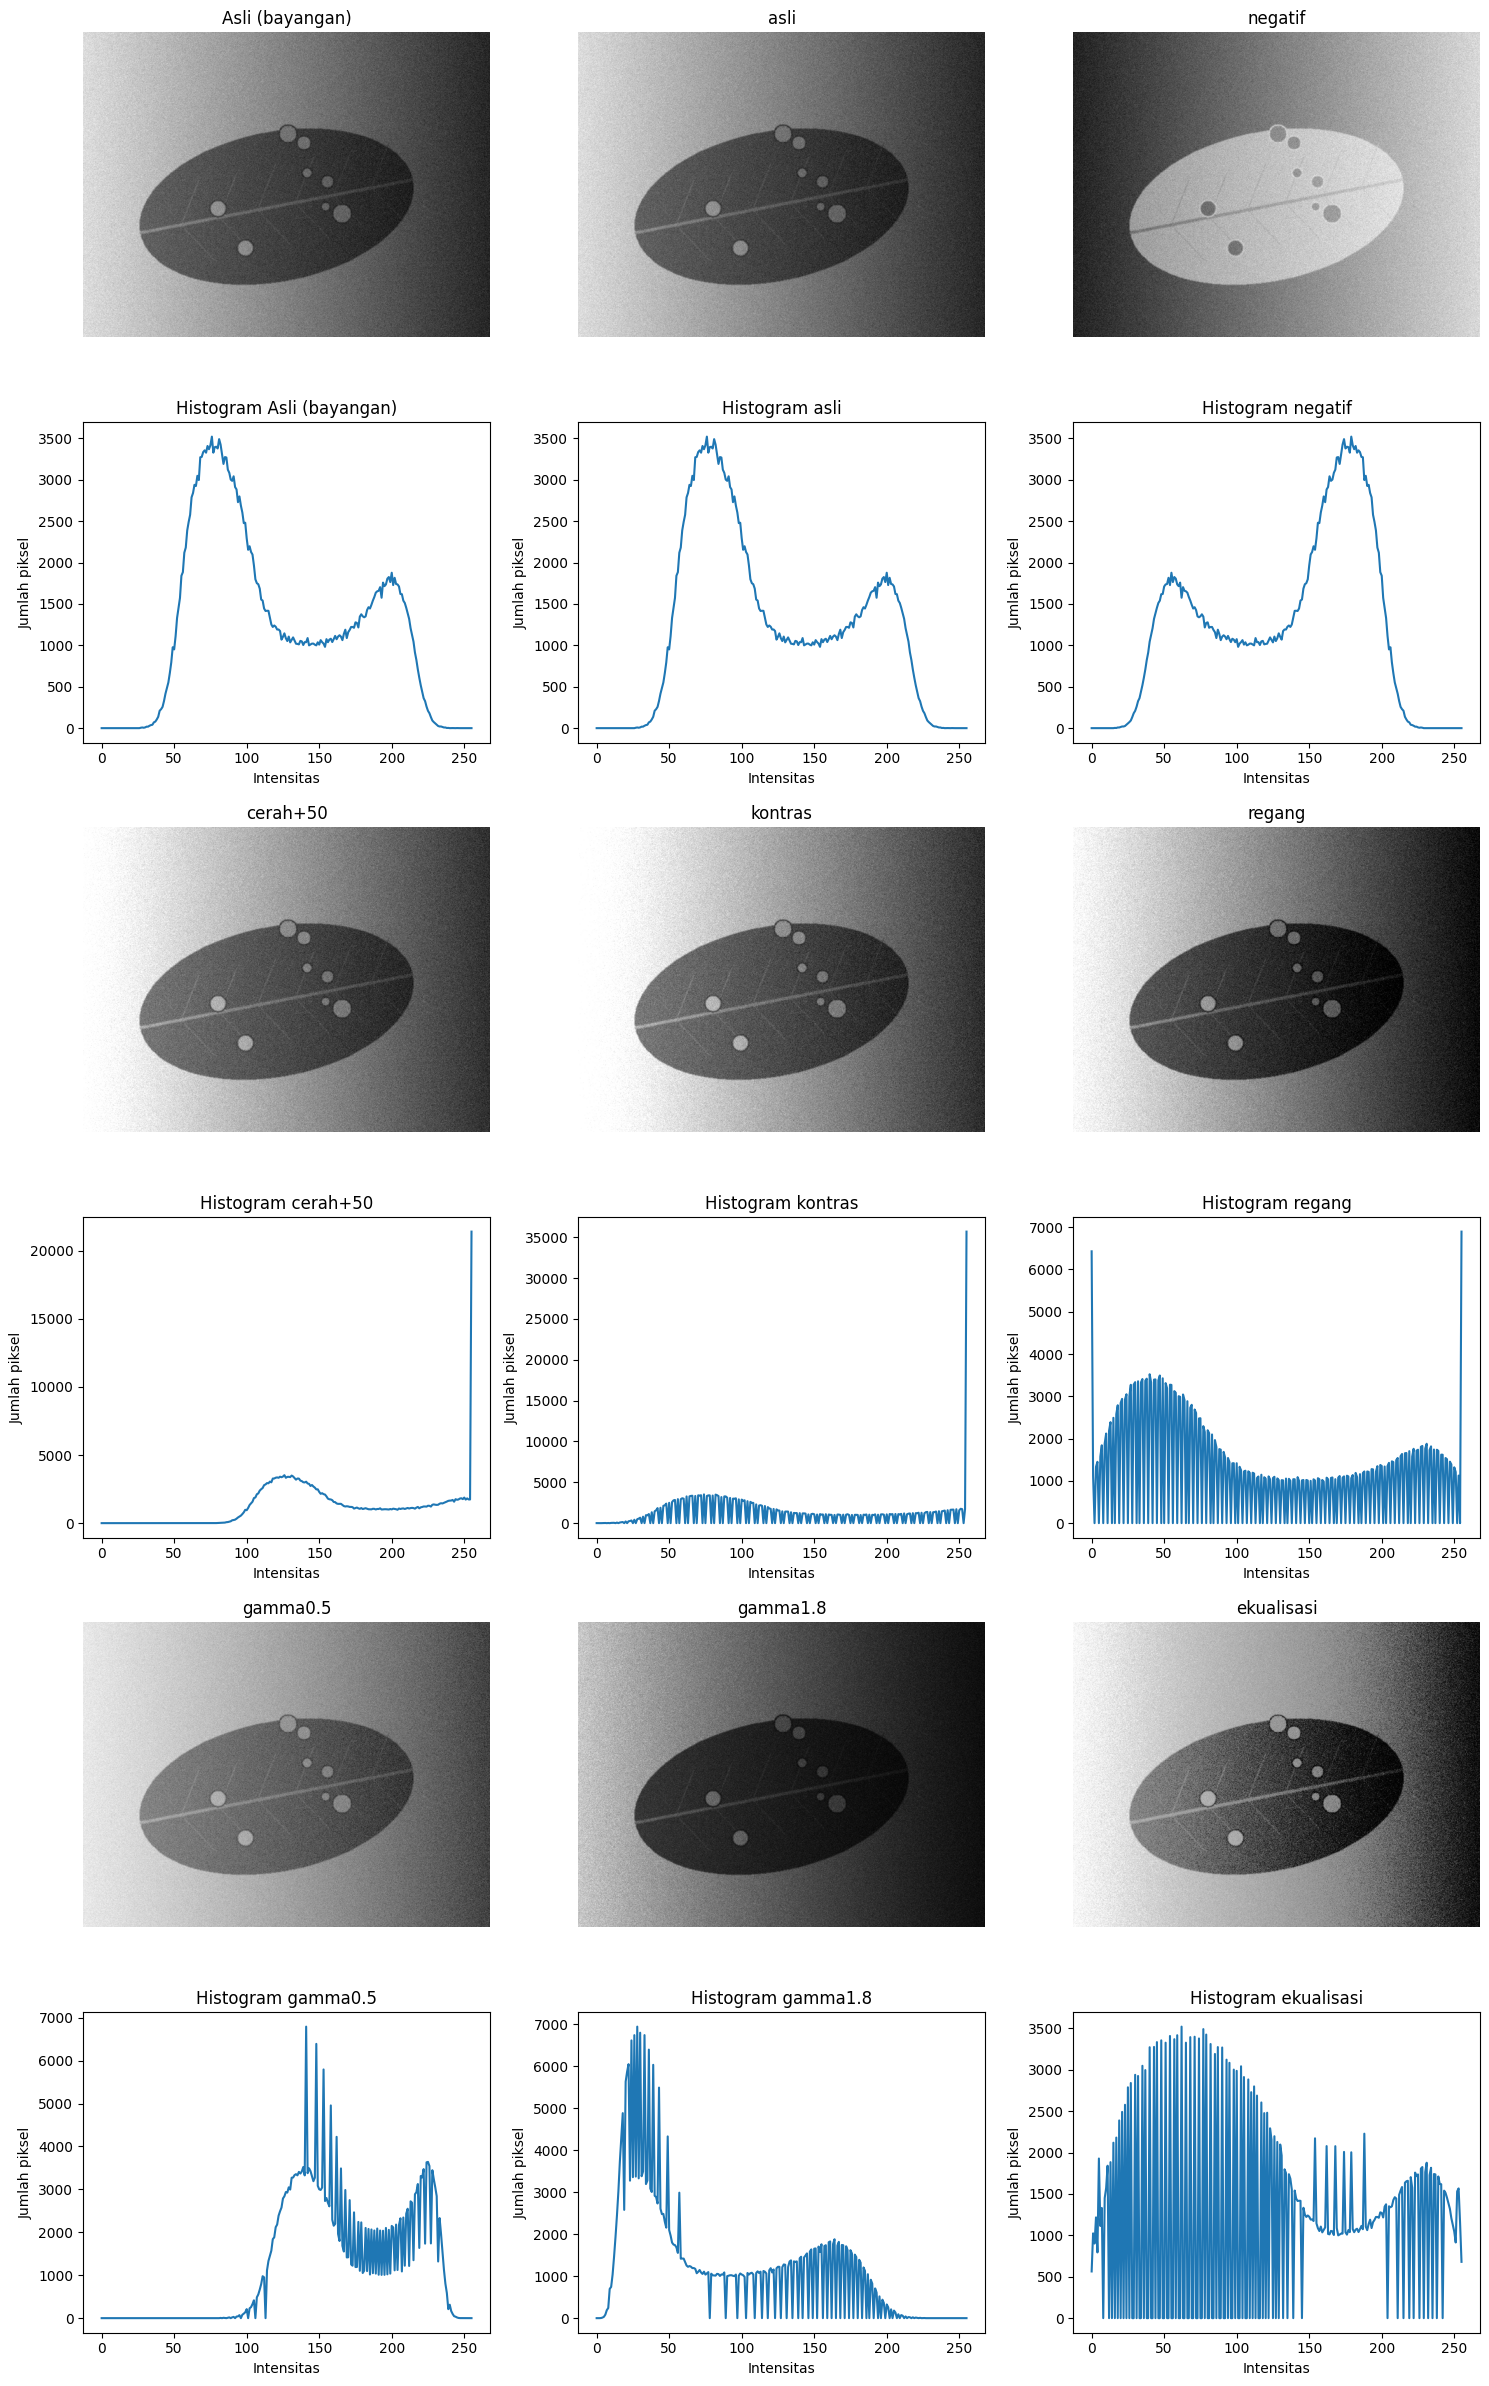

In [36]:
nama_hasil = list(hasil.keys())

# Tambahkan citra asli (bayangan) sebagai metode pertama
citra_tampil = {"Asli (bayangan)": gray}
citra_tampil.update(hasil)

nama_hasil = list(citra_tampil.keys())

# Pastikan jumlah metode 9
fig, ax = plt.subplots(6, 3, figsize=(15, 24))

for i, nm in enumerate(nama_hasil[:9]):
    baris = i // 3
    kolom = i % 3

    citra = citra_tampil[nm]

    # Citra pada baris ganjil
    ax[baris * 2, kolom].imshow(citra, cmap="gray")
    ax[baris * 2, kolom].set_title(nm)
    ax[baris * 2, kolom].axis("off")

    # Histogram tepat di bawah citra
    hist = cv2.calcHist([citra], [0], None, [256], [0, 256])
    ax[baris * 2 + 1, kolom].plot(hist)
    ax[baris * 2 + 1, kolom].set_xlabel("Intensitas")
    ax[baris * 2 + 1, kolom].set_ylabel("Jumlah piksel")
    ax[baris * 2 + 1, kolom].set_title(f"Histogram {nm}")

plt.tight_layout()
plt.savefig("../hasil/b3_perbandingan_semua_metode.png",
            dpi=150, bbox_inches="tight")
plt.show()

**Kode 3.3 Eksperimen CLAHE**

clip=1.0 tile=4: KB=2.29
clip=1.0 tile=8: KB=2.19
clip=1.0 tile=16: KB=1.94
clip=2.0 tile=4: KB=2.37
clip=2.0 tile=8: KB=2.09
clip=2.0 tile=16: KB=1.87
clip=4.0 tile=4: KB=2.16
clip=4.0 tile=8: KB=1.72
clip=4.0 tile=16: KB=1.58


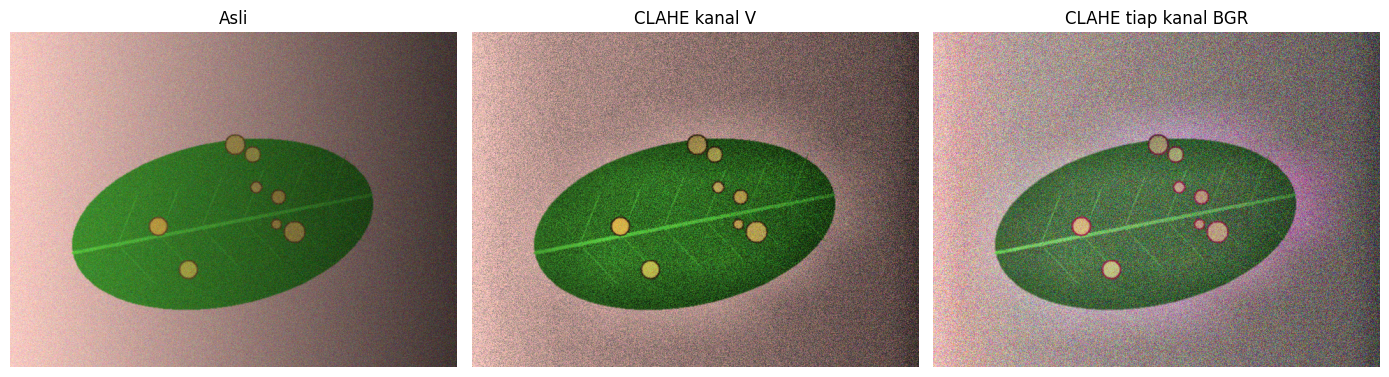

In [37]:
# eksperimen parameter CLAHE
from utils_cv import tampil
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:

        c = cv2.createCLAHE(
            clipLimit=clip,
            tileGridSize=(tile, tile)
        ).apply(gray)

        print(f"clip={clip} tile={tile}: KB={kontras_bercak(c, md, mb):.2f}")


# CLAHE pada citra warna: kanal V (benar) dan tiap kanal BGR (bandingkan)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

via_bgr = cv2.merge([
    clahe.apply(c) for c in cv2.split(img)
])

tampil(
    [img, via_v, via_bgr],
    ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"]
)

##**perbaikan untuk setiap kondisi**


=== Kondisi Gelap | Metode gamma0.5 ===
teh_042.png: KB awal=4.59, KB setelah=3.60
teh_022.png: KB awal=1.89, KB setelah=1.44

=== Kondisi Terang | Metode gamma1.8 ===
teh_043.png: KB awal=3.14, KB setelah=3.43
teh_023.png: KB awal=3.15, KB setelah=3.41

=== Kondisi Kontras rendah | Metode CLAHE ===
teh_044.png: KB awal=1.68, KB setelah=1.20
teh_024.png: KB awal=0.80, KB setelah=0.77

=== Kondisi Bayangan | Metode CLAHE ===
teh_045.png: KB awal=1.50, KB setelah=2.09
teh_025.png: KB awal=0.86, KB setelah=1.51


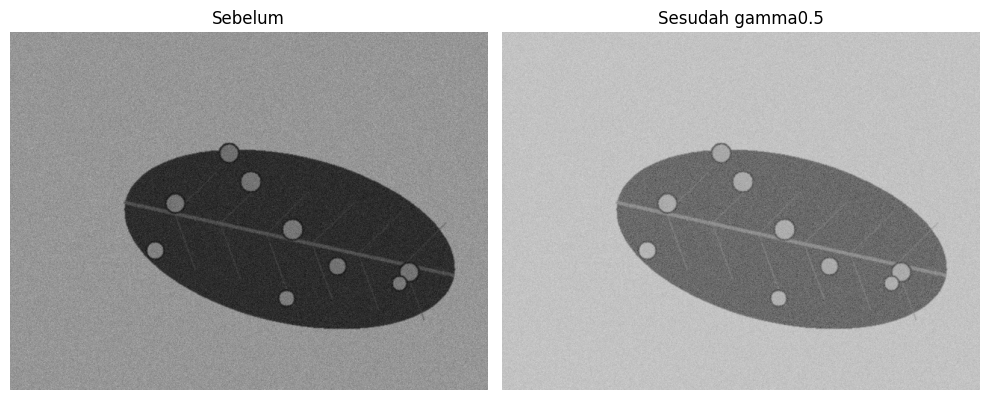

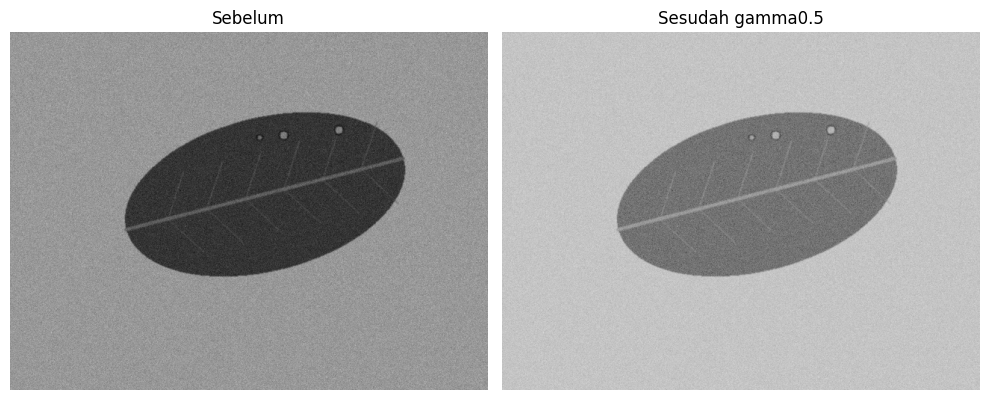

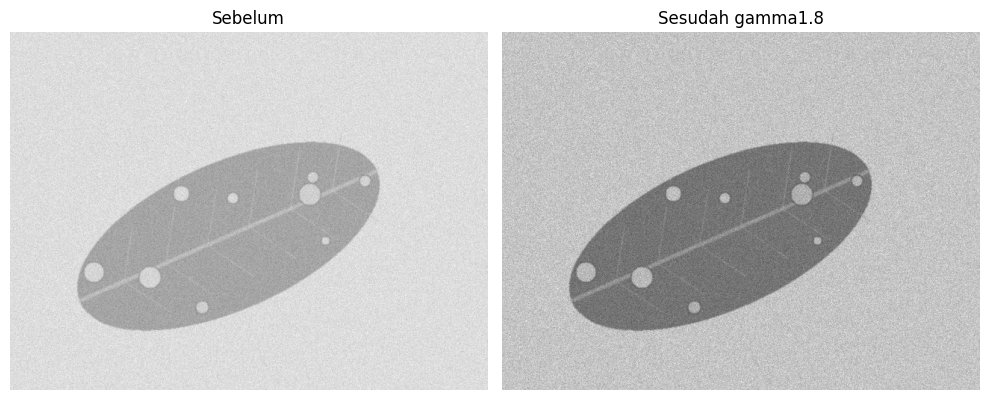

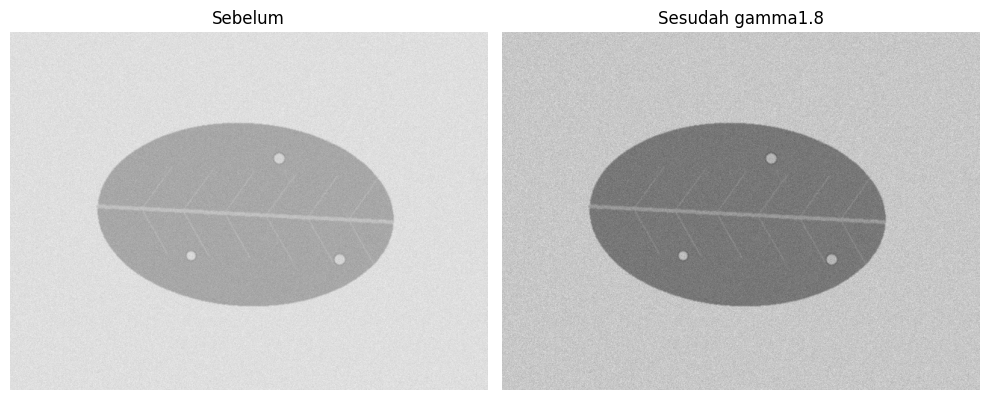

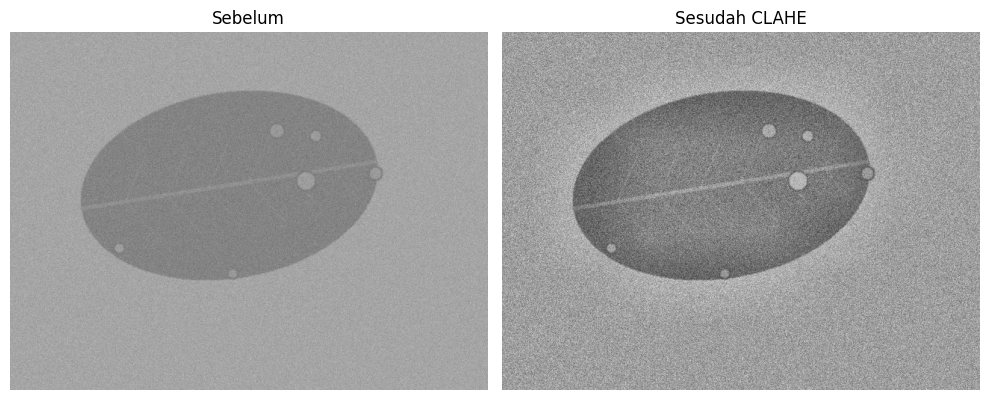

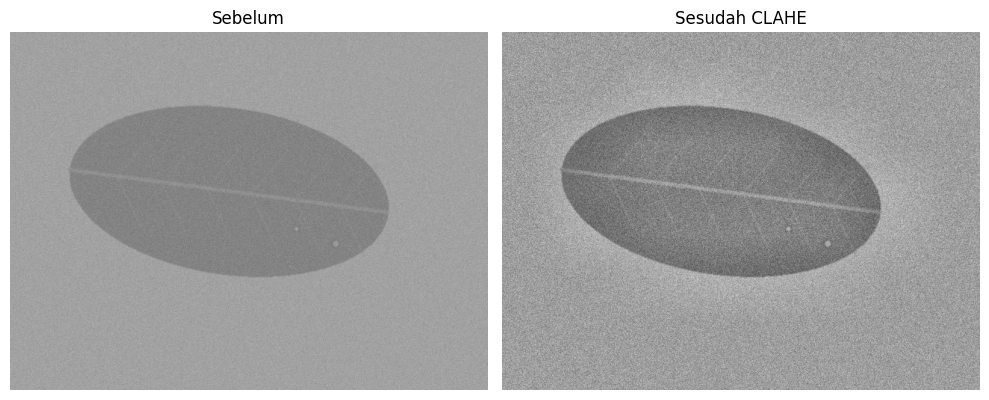

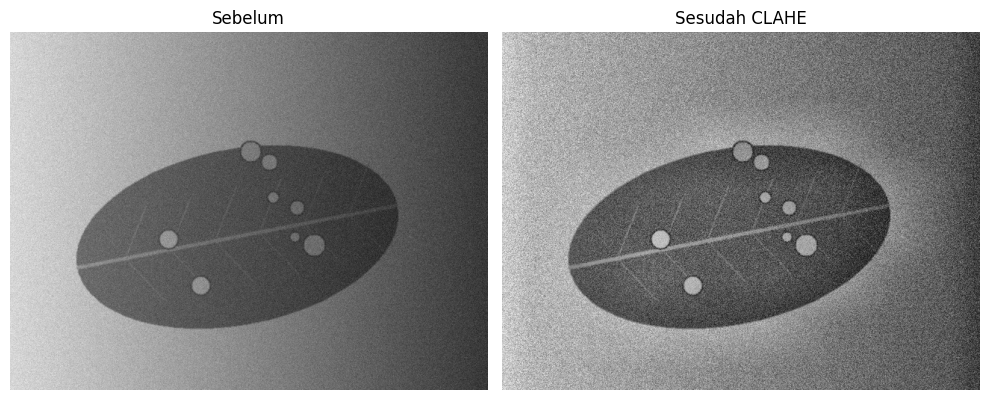

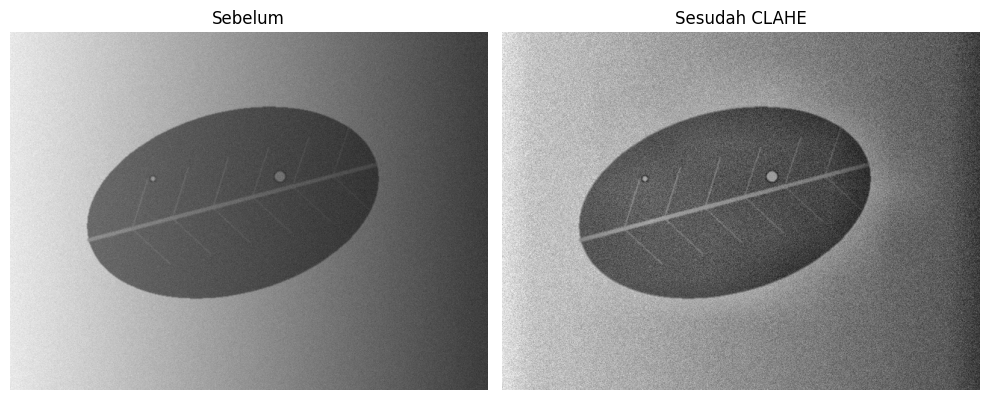

In [38]:
# Fungsi koreksi gamma
def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)


# Daftar citra dan metode perbaikan
percobaan = [
    ("Gelap", ["teh_042.png", "teh_022.png"], "gamma0.5"),
    ("Terang", ["teh_043.png", "teh_023.png"], "gamma1.8"),
    ("Kontras rendah", ["teh_044.png", "teh_024.png"], "CLAHE"),
    ("Bayangan", ["teh_045.png", "teh_025.png"], "CLAHE")
]

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

for kondisi, daftar, metode in percobaan:
    print(f"\n=== Kondisi {kondisi} | Metode {metode} ===")

    for nama in daftar:
        img = baca(f"../data/sintetis/citra/{nama}")
        md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
        mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

        # Terapkan perbaikan
        if metode == "gamma0.5":
            perbaikan = cv2.LUT(gray, gamma_lut(0.5))

        elif metode == "gamma1.8":
            perbaikan = cv2.LUT(gray, gamma_lut(1.8))

        elif metode == "CLAHE":
            perbaikan = clahe.apply(gray)

        kb_awal = kontras_bercak(gray, md, mb)
        kb_akhir = kontras_bercak(perbaikan, md, mb)

        print(
            f"{nama}: KB awal={kb_awal:.2f}, "
            f"KB setelah={kb_akhir:.2f}"
        )

        tampil(
            [gray, perbaikan],
            ["Sebelum", f"Sesudah {metode}"],
            baris=1,
            ukuran=(10, 4)
        )